In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

In [3]:
import glob

path = "*.csv"  # change to your folder path
files = glob.glob(path)

df_list = []

for file in files:
    temp = pd.read_csv(file)
    df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)

C:\Users\dell\AppData\Local\Temp\ipykernel_1824\513096305.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat(df_list, ignore_index=True)


In [6]:
df = df.drop(columns=['states', 'rto_codes'])
df

,date,city_name,air_quality_status,aqi_value
0,30-Apr-2025,Tirupati,Good,47.0
1,30-Apr-2025,Kadapa,Satisfactory,67.0
2,30-Apr-2025,Chittoor,Satisfactory,68.0
3,30-Apr-2025,Tirumala,Good,47.0
4,30-Apr-2025,Vijayawada,Satisfactory,60.0
...,...,...,...,...
239074,01-Apr-2022,Haldia,Good,39.0
239075,01-Apr-2022,Kolkata,Satisfactory,70.0
239076,01-Apr-2022,Asansol,Moderate,119.0
239077,01-Apr-2022,Howrah,Satisfactory,82.0


In [10]:
df.columns = ['date', 'city', 'status', 'aqi']

df['date'] = pd.to_datetime(df['date'], dayfirst=True, errors='coerce')

df = df.dropna(subset=['date'])

df = df.sort_values(by=['city', 'date'])

df['aqi'] = df['aqi'].astype(int)

In [11]:
df['rolling_mean'] = df.groupby('city')['aqi'].transform(lambda x: x.rolling(7).mean())
df['rolling_std'] = df.groupby('city')['aqi'].transform(lambda x: x.rolling(7).std())

In [12]:
df['lag1'] = df.groupby('city')['aqi'].shift(1)
df['lag2'] = df.groupby('city')['aqi'].shift(2)
df['lag3'] = df.groupby('city')['aqi'].shift(3)

In [13]:
threshold = 20  # you can tune this

df['spike'] = (df['aqi'] > (df['rolling_mean'] + threshold)).astype(int)

In [14]:
df = df.dropna()

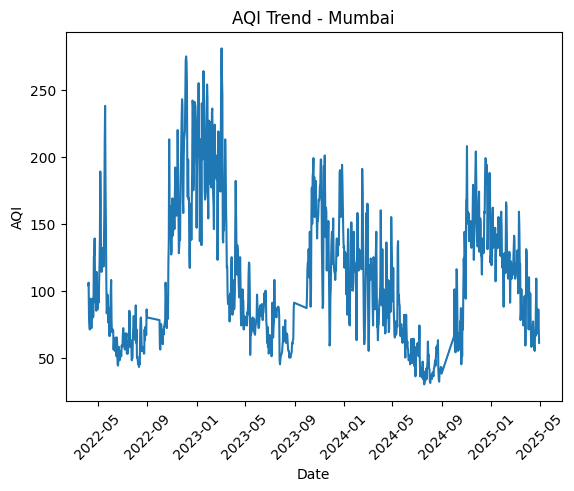

In [15]:
city = "Mumbai"  # change

city_df = df[df['city'] == city]

plt.figure()
plt.plot(city_df['date'], city_df['aqi'])
plt.title(f"AQI Trend - {city}")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.show()

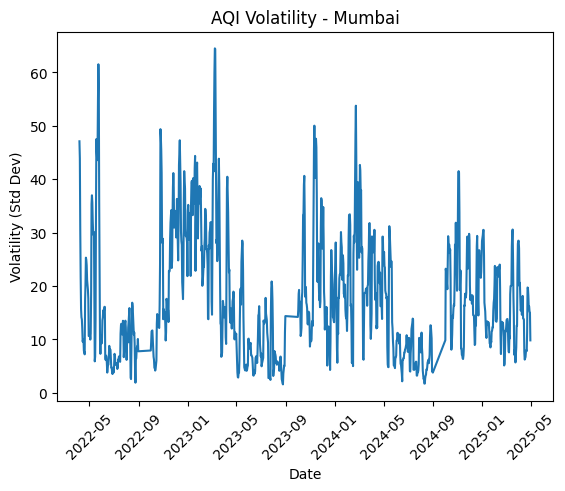

In [16]:
plt.figure()
plt.plot(city_df['date'], city_df['rolling_std'])
plt.title(f"AQI Volatility - {city}")
plt.xlabel("Date")
plt.ylabel("Volatility (Std Dev)")
plt.xticks(rotation=45)
plt.show()

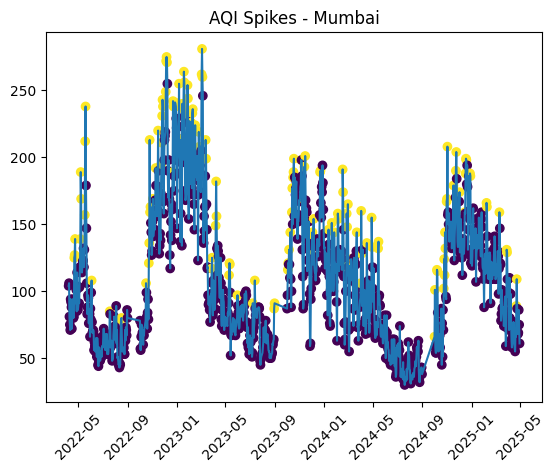

In [17]:
plt.figure()
plt.plot(city_df['date'], city_df['aqi'])
plt.scatter(city_df['date'], city_df['aqi'], c=city_df['spike'])
plt.title(f"AQI Spikes - {city}")
plt.xticks(rotation=45)
plt.show()

In [18]:
features = ['lag1', 'lag2', 'lag3', 'rolling_mean', 'rolling_std']
X = df[features]
y = df['spike']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

In [20]:
model = RandomForestClassifier(n_estimators=100)
model.fit(X_train, y_train)

RandomForestClassifier()

In [21]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8568715825116109
              precision    recall  f1-score   support

           0       0.88      0.95      0.92     36287
           1       0.63      0.38      0.47      7422

    accuracy                           0.86     43709
   macro avg       0.76      0.67      0.70     43709
weighted avg       0.84      0.86      0.84     43709



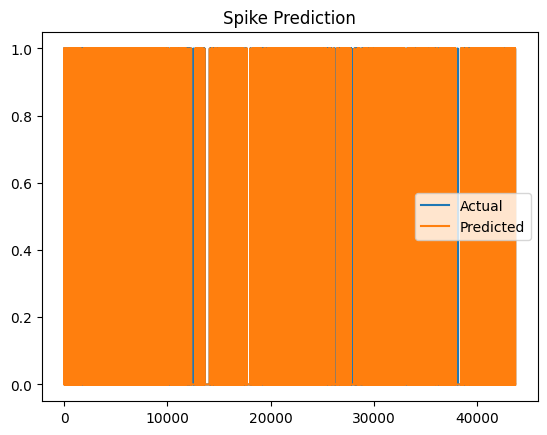

In [22]:
plt.figure()
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.legend()
plt.title("Spike Prediction")
plt.show()

In [23]:
volatility = df.groupby('city')['rolling_std'].mean().sort_values(ascending=False)
print(volatility.head(10))

city
Mandi Gobindgarh    52.498796
Byrnihat            51.656458
Sri Ganganagar      50.186139
Dharuhera           46.340022
Begusarai           46.227906
Muzaffarnagar       44.965982
Greater Noida       44.954828
Rohtak              43.865888
Manesar             43.625392
Charkhi Dadri       43.410196
Name: rolling_std, dtype: float64


In [24]:
volatility = df.groupby('city')['rolling_std'].mean()

top_5_high = volatility.sort_values(ascending=False).head(5)
top_5_low = volatility.sort_values(ascending=True).head(5)

selected_cities = list(top_5_high.index) + list(top_5_low.index)

print(selected_cities)

['Mandi Gobindgarh', 'Byrnihat', 'Sri Ganganagar', 'Dharuhera', 'Begusarai', 'Bagalkot', 'Chamarajanagar', 'Tirunelveli', 'Kannur', 'Kozhikode']


In [ ]:
##“Cities were selected based on AQI volatility to compare stable vs unstable pollution environments.”

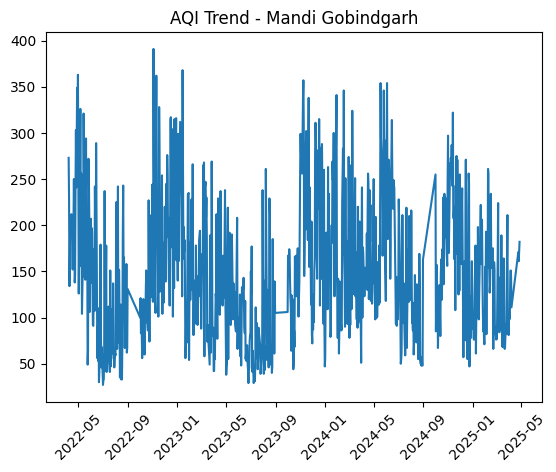

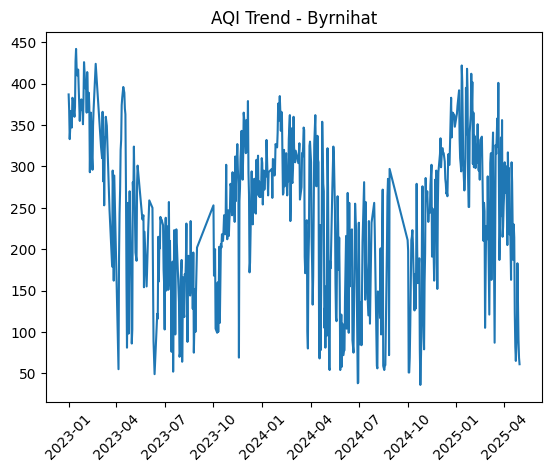

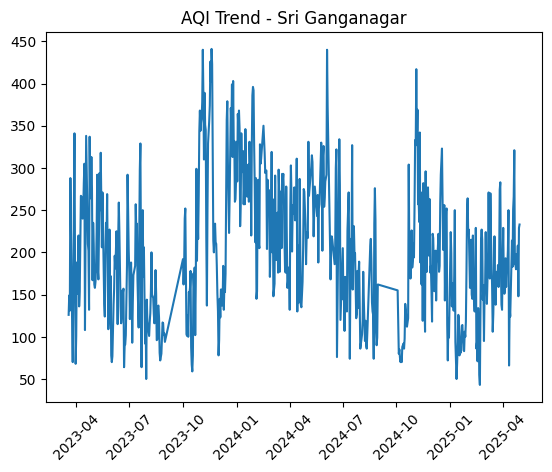

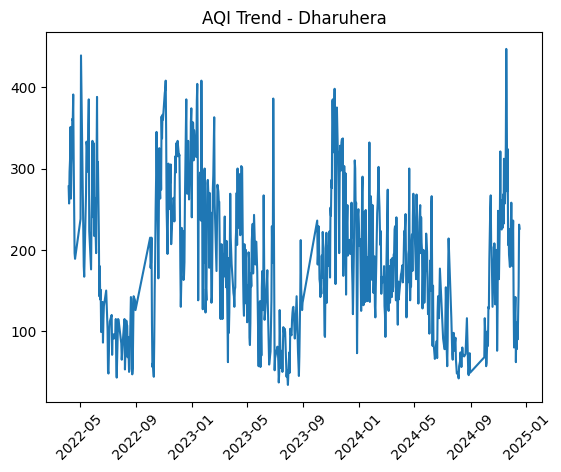

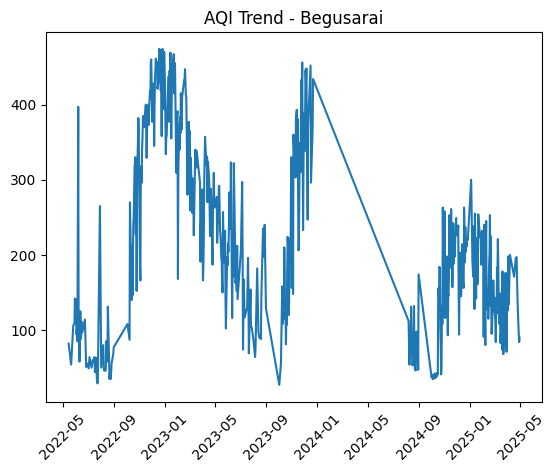

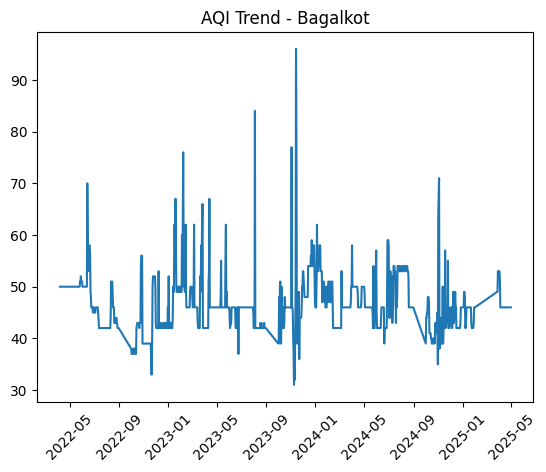

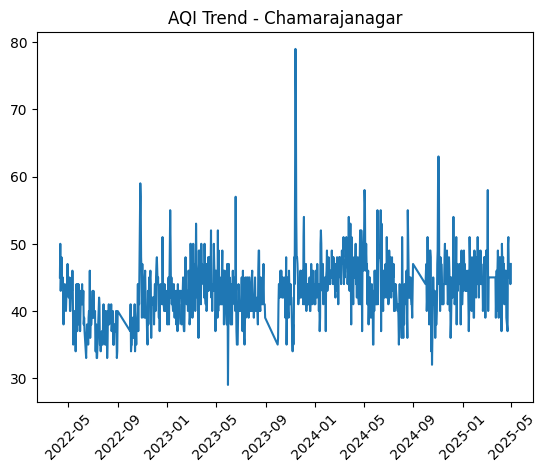

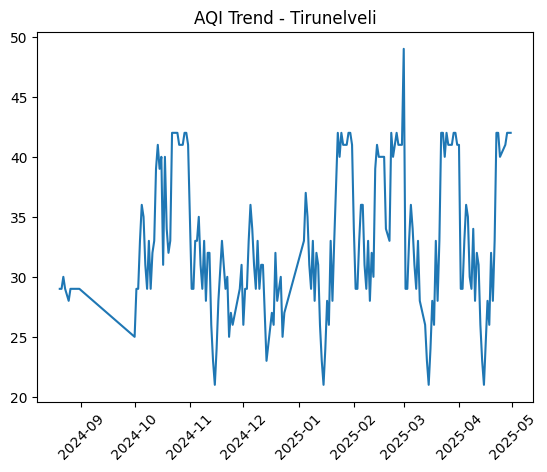

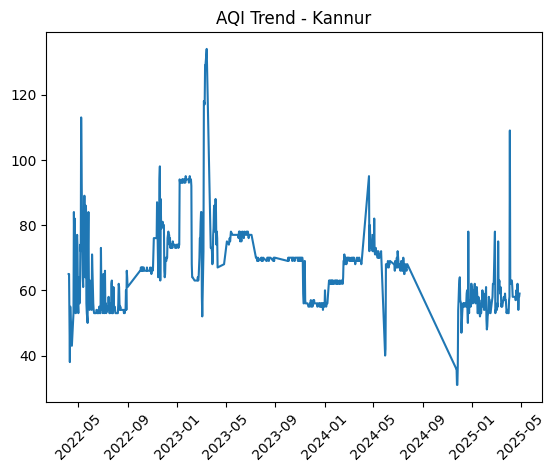

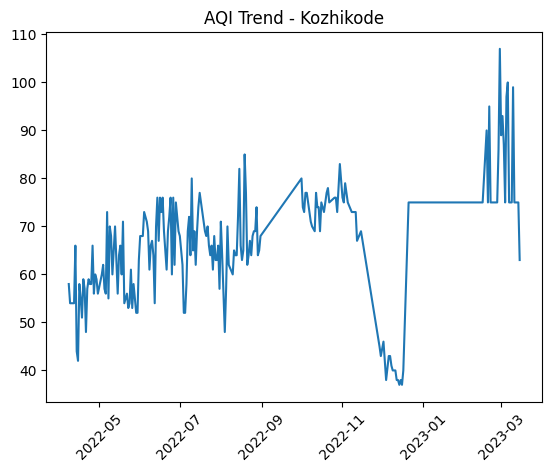

In [25]:
for city in selected_cities:
    city_df = df[df['city'] == city]

    plt.figure()
    plt.plot(city_df['date'], city_df['aqi'])
    plt.title(f"AQI Trend - {city}")
    plt.xticks(rotation=45)
    plt.show()

In [29]:
df_selected = df[df['city'].isin(selected_cities)].copy()

In [33]:
df_selected = df[df['city'].isin(selected_cities)].copy()

features = ['lag1', 'lag2', 'lag3', 'rolling_mean', 'rolling_std']

X = df_selected[features]
y = df_selected['spike']

In [42]:
train_list = []
test_list = []

for city in selected_cities:
    city_df = df_selected[df_selected['city'] == city].sort_values('date')
    
    split_idx = int(len(city_df) * 0.8)
    
    train_list.append(city_df.iloc[:split_idx])
    test_list.append(city_df.iloc[split_idx:])

train_df = pd.concat(train_list)
test_df = pd.concat(test_list)

In [43]:
features = ['lag1', 'lag2', 'lag3', 'rolling_mean', 'rolling_std']

X_train = train_df[features]
y_train = train_df['spike']

X_test = test_df[features]
y_test = test_df['spike']

In [44]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

test_df['pred'] = y_pred

In [45]:
for city in selected_cities:
    city_data = test_df[test_df['city'] == city]
    
    acc = (city_data['spike'] == city_data['pred']).mean()
    print(f"{city} Accuracy: {acc:.2f}")

Mandi Gobindgarh Accuracy: 0.56
Byrnihat Accuracy: 0.51
Sri Ganganagar Accuracy: 0.57
Dharuhera Accuracy: 0.61
Begusarai Accuracy: 0.62
Bagalkot Accuracy: 0.99
Chamarajanagar Accuracy: 1.00
Tirunelveli Accuracy: 1.00
Kannur Accuracy: 0.98
Kozhikode Accuracy: 0.98


In [46]:
for city in selected_cities:
    city_data = df_selected[df_selected['city'] == city]
    
    spike_rate = city_data['spike'].mean()
    print(f"{city} Spike Rate: {spike_rate:.3f}")

Mandi Gobindgarh Spike Rate: 0.333
Byrnihat Spike Rate: 0.355
Sri Ganganagar Spike Rate: 0.327
Dharuhera Spike Rate: 0.336
Begusarai Spike Rate: 0.324
Bagalkot Spike Rate: 0.004
Chamarajanagar Spike Rate: 0.001
Tirunelveli Spike Rate: 0.000
Kannur Spike Rate: 0.013
Kozhikode Spike Rate: 0.016


In [47]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.78      0.85      1103
           1       0.39      0.75      0.51       207

    accuracy                           0.77      1310
   macro avg       0.66      0.76      0.68      1310
weighted avg       0.86      0.77      0.80      1310



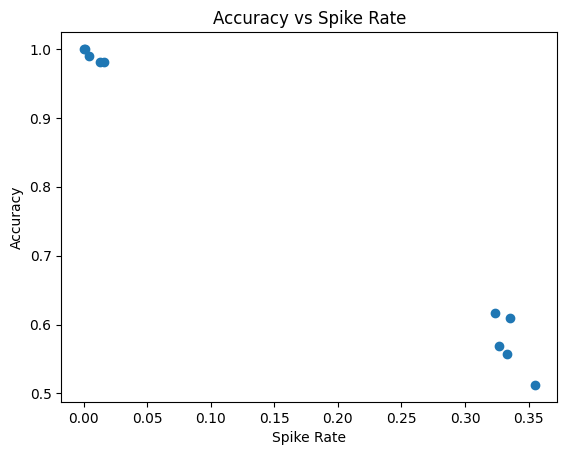

In [48]:
acc_list = []
spike_list = []

for city in selected_cities:
    city_test = test_df[test_df['city'] == city]
    city_all = df_selected[df_selected['city'] == city]
    
    acc = (city_test['spike'] == city_test['pred']).mean()
    spike_rate = city_all['spike'].mean()
    
    acc_list.append(acc)
    spike_list.append(spike_rate)

plt.figure()
plt.scatter(spike_list, acc_list)
plt.xlabel("Spike Rate")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Spike Rate")
plt.show()

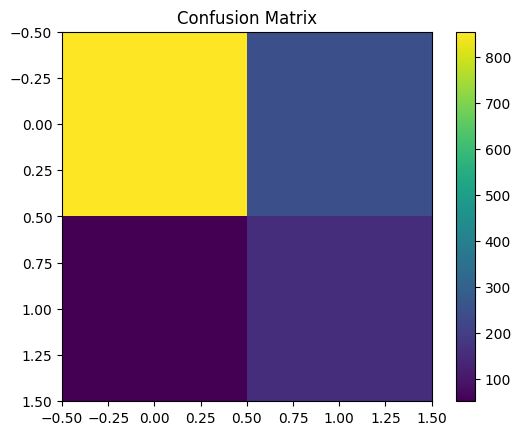

In [49]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure()
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.colorbar()
plt.show()

Text(0, 0.5, 'True Label')

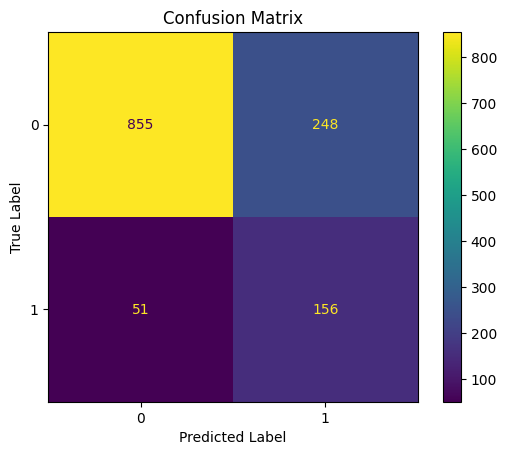

In [54]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

NameError: name 'spike_rates' is not defined

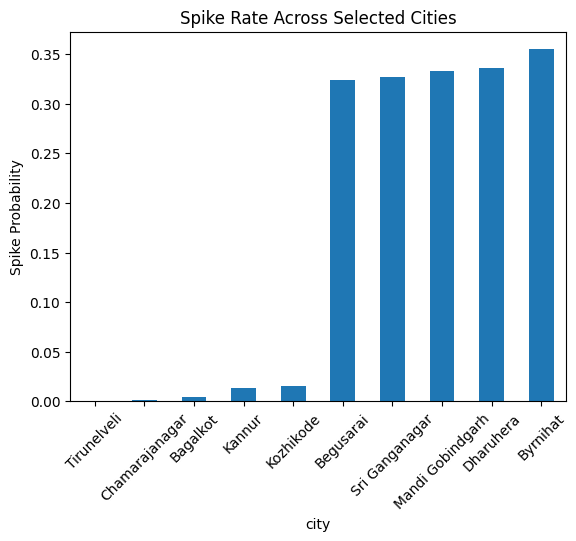

In [50]:
spike_rate = df_selected.groupby('city')['spike'].mean()

spike_rate.loc[selected_cities].sort_values().plot(kind='bar')
plt.title("Spike Rate Across Selected Cities")
plt.ylabel("Spike Probability")
plt.xticks(rotation=45)
plt.show()

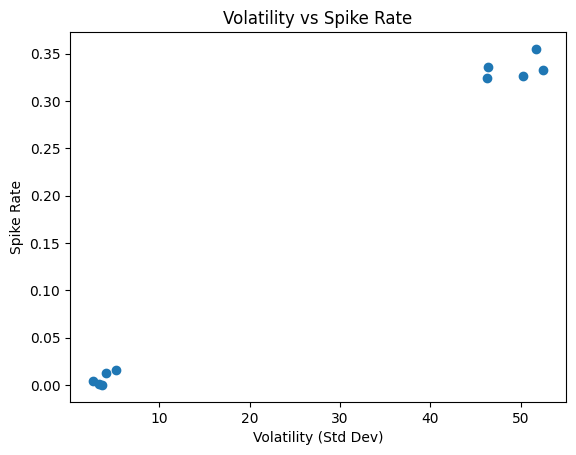

In [51]:
volatility = df_selected.groupby('city')['rolling_std'].mean()

vol = []
spike = []

for city in selected_cities:
    vol.append(volatility[city])
    spike.append(spike_rate[city])

plt.figure()
plt.scatter(vol, spike)
plt.xlabel("Volatility (Std Dev)")
plt.ylabel("Spike Rate")
plt.title("Volatility vs Spike Rate")
plt.show()

In [52]:
def classify_city(rate):
    if rate > 0.2:
        return "High Volatility"
    elif rate > 0.05:
        return "Medium Volatility"
    else:
        return "Low Volatility"

city_category = spike_rate.apply(classify_city)
print(city_category)

city
Bagalkot             Low Volatility
Begusarai           High Volatility
Byrnihat            High Volatility
Chamarajanagar       Low Volatility
Dharuhera           High Volatility
Kannur               Low Volatility
Kozhikode            Low Volatility
Mandi Gobindgarh    High Volatility
Sri Ganganagar      High Volatility
Tirunelveli          Low Volatility
Name: spike, dtype: object


In [57]:
spike_rates = []
accuracies = []

for city in selected_cities:
    city_data = df_selected[df_selected['city'] == city]
    
    spike_rate = city_data['spike'].mean()
    
    city_test = test_df[test_df['city'] == city]
    acc = (city_test['spike'] == city_test['pred']).mean()
    
    spike_rates.append(spike_rate)
    accuracies.append(acc)

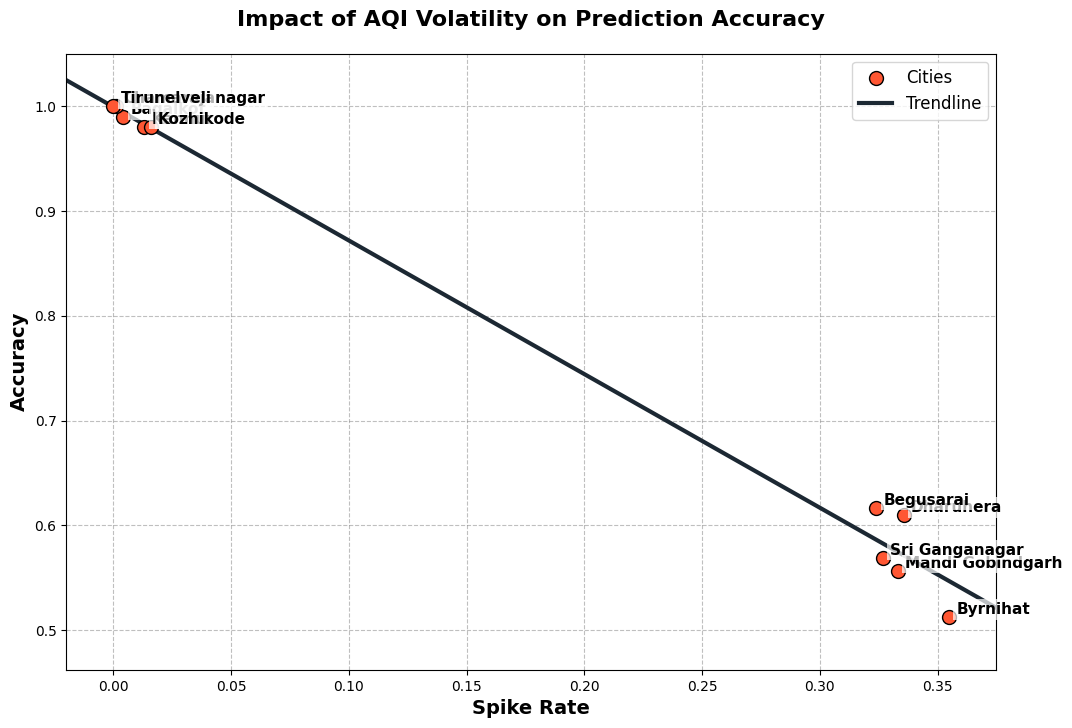

In [79]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

# 1. Use high-contrast colors and larger markers
plt.scatter(spike_rates, accuracies, color='#FF5733', s=100, edgecolors='black', label='Cities', zorder=3)

# 2. Make the trendline thicker and a contrasting color (deep navy)
z = np.polyfit(spike_rates, accuracies, 1)
p = np.poly1d(z)
# Create a wider range for the line to span the plot
x_plot = np.linspace(min(spike_rates) - 0.02, max(spike_rates) + 0.02, 100)
plt.plot(x_plot, p(x_plot), color='#1C2833', linewidth=3, label='Trendline', zorder=2)

# 3. Enhanced label visibility with background boxes
for i, city in enumerate(selected_cities):
    plt.text(spike_rates[i] + 0.003, accuracies[i] + 0.003, city, 
             fontsize=11, 
             fontweight='bold',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))

# Zoom and grid styling
plt.xlim(min(spike_rates) - 0.02, max(spike_rates) + 0.02)
plt.ylim(min(accuracies) - 0.05, max(accuracies) + 0.05)

# 4. Make labels and titles bold for better readability
plt.xlabel("Spike Rate", fontsize=14, fontweight='bold')
plt.ylabel("Accuracy", fontsize=14, fontweight='bold')
plt.title("Impact of AQI Volatility on Prediction Accuracy", fontsize=16, fontweight='bold', pad=20)

plt.grid(True, linestyle='--', color='gray', alpha=0.5) 
plt.legend(fontsize=12)

plt.show()

In [53]:
classification_report(y_test, y_pred)

'              precision    recall  f1-score   support\n\n           0       0.94      0.78      0.85      1103\n           1       0.39      0.75      0.51       207\n\n    accuracy                           0.77      1310\n   macro avg       0.66      0.76      0.68      1310\nweighted avg       0.86      0.77      0.80      1310\n'